**Importar as bibliotecas**

In [592]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Carregar o CSV e mostrar as 10 primeiras linhas**

In [593]:
df = pd.read_csv("data/heart_disease_uci.csv")
df.head(10)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
5,6,56,Male,Cleveland,atypical angina,120.0,236.0,False,normal,178.0,False,0.8,upsloping,0.0,normal,0
6,7,62,Female,Cleveland,asymptomatic,140.0,268.0,False,lv hypertrophy,160.0,False,3.6,downsloping,2.0,normal,3
7,8,57,Female,Cleveland,asymptomatic,120.0,354.0,False,normal,163.0,True,0.6,upsloping,0.0,normal,0
8,9,63,Male,Cleveland,asymptomatic,130.0,254.0,False,lv hypertrophy,147.0,False,1.4,flat,1.0,reversable defect,2
9,10,53,Male,Cleveland,asymptomatic,140.0,203.0,True,lv hypertrophy,155.0,True,3.1,downsloping,0.0,reversable defect,1


**Contar quantas linhas e colunas o dataset tem**

In [594]:
linhas = df.shape[0]
colunas = df.shape[1]

print("linhas:", linhas)
print("colunas:", colunas)

linhas: 920
colunas: 16


**Ver o tipo de cada coluna e quantos valores preenchidos ela tem**

In [595]:
print("Informações gerais:")
df.info()

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


**Calcular a quantidade e a porcentagem de valores nulos em cada coluna**

In [596]:
print("Informações sobre valores nulos:")

valores_nulos = df.isnull().sum()
porcentagem_nulos = (valores_nulos / linhas) * 100
porcentagem_nulos = porcentagem_nulos.round(1)

pd.DataFrame({"Valores Nulos": valores_nulos, "Porcentagem (%)": porcentagem_nulos})


Informações sobre valores nulos:


,Valores Nulos,Porcentagem (%)
id,0,0.0
age,0,0.0
sex,0,0.0
dataset,0,0.0
cp,0,0.0
trestbps,59,6.4
chol,30,3.3
fbs,90,9.8
restecg,2,0.2
thalch,55,6.0


**Listar os valores do diagnóstico (`num`) e contar quantos pacientes há em cada um**

In [597]:
coluna = "num"

print(f"Valores únicos de {coluna}:")
print(df[coluna].unique())

print("\nQuantidade por categoria:")
print(df[coluna].value_counts().sort_index())


Valores únicos de num:
[0 2 1 3 4]

Quantidade por categoria:
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


**Criar a coluna `eh_doente` (`num > 0`) e contar doentes e não doentes**

In [598]:
df["eh_doente"] = df["num"] > 0 # identifica pacientes doentes (num > 0) e não doentes (num = 0)

print("True (Doentes):", df["eh_doente"].value_counts()[True])
print("False (Não Doentes):", df["eh_doente"].value_counts()[False])


True (Doentes): 509
False (Não Doentes): 411


**Calcular a porcentagem de doentes no dataset inteiro**

In [599]:
porcentagem_de_doentes = df["eh_doente"].mean() * 100

print(f"Percentual de doentes: {porcentagem_de_doentes:.1f}%")

Percentual de doentes: 55.3%


**Calcular a porcentagem de doentes e não doentes em cada hospital**

In [600]:
# calcular o percentual de pacientes doentes e não doentes em cada hospital

por_hospital = pd.crosstab( # crosstab já ignora linhas com valores ausentes nas coluna utilizadas
    df["dataset"],
    df["num"] > 0,
    normalize="index" # calcula os percentuais dentro de cada hospital
) * 100

por_hospital = por_hospital.rename(columns={ # renomeia as colunas "False" e "True"
    False: "Não doentes (%)",
    True: "Doentes (%)"
})

display(por_hospital.round(1))



num,Não doentes (%),Doentes (%)
dataset,,
Cleveland,54.3,45.7
Hungary,63.8,36.2
Switzerland,6.5,93.5
VA Long Beach,25.5,74.5


**Calcular a quantidade e a porcentagem de nulos em `ca`, `thal` e `slope` em cada hospital**

In [601]:
colunas_para_analise = ["ca", "thal", "slope"]

# Quantidade de valores ausentes por hospital
quantidade_ausentes = df.groupby("dataset")[colunas_para_analise].apply(
    lambda grupo: grupo.isnull().sum()
)

# Percentual de valores ausentes por hospital
percentual = df.groupby("dataset")[colunas_para_analise].apply(
    lambda grupo: grupo.isnull().mean() * 100
)

# Combinar as duas tabelas
resumo_nulos = pd.concat(
    {
        "Quantidade de nulos": quantidade_ausentes,
        "Percentual de nulos (%)": percentual.round(1)
    },
    axis=1
)

display(resumo_nulos)


Quantidade de nulos            Percentual de nulos (%)        \
                               ca thal slope                      ca  thal   
dataset                                                                      
Cleveland                       5    3     1                     1.6   1.0   
Hungary                       290  265   189                    99.0  90.4   
Switzerland                   118   52    17                    95.9  42.3   
VA Long Beach                 198  166   102                    99.0  83.0   

                     
              slope  
dataset              
Cleveland       0.3  
Hungary        64.5  
Switzerland    13.8  
VA Long Beach  51.0

O hospital de Cleveland apresenta uma pouquissimos registros faltantes nas variáveis analisadas, enquanto Hungary, Switzerland e VA Long Beach possuem altos índices de ausência, especialmente na variável "ca". Esse comportamento sugere que os valores ausentes podem estar relacionados às diferenças nos processos de coleta e disponibilidade de exames entre os estudos de origem. Ponto de atenção: a variável ca exige uma avaliação cuidadosa antes da modelagem, pois sua elevada ausência em três hospitais pode comprometer a representatividade dos dados. A exclusão desses registros também pode introduzir viés na análise.

**Mostrar as estatísticas descritivas e contar, por hospital, os zeros impossíveis em `trestbps` e `chol`**

In [602]:
print(df.describe())

# Filtrar registros com valores iguais a zero
pressao_arterial_igual_a_zero = df[df["trestbps"] == 0]
colesterol_igual_a_zero = df[df["chol"] == 0]

# Contabilizar ocorrências por hospital
resumo_zeros = pd.DataFrame({
    "Pressão arterial (trestbps = 0)":
        pressao_arterial_igual_a_zero["dataset"].value_counts(),

    "Colesterol (chol = 0)":
        colesterol_igual_a_zero["dataset"].value_counts()
})

# Incluir todos os hospitais, mesmo aqueles sem ocorrências
resumo_zeros = resumo_zeros.reindex(
    sorted(df["dataset"].dropna().unique()),
    fill_value=0
).fillna(0).astype(int)

resumo_zeros.index.name = "Hospital"

# Adicionar linha com o total
resumo_zeros.loc["Total"] = resumo_zeros.sum()

display(resumo_zeros)




               id         age    trestbps        chol      thalch     oldpeak  \
count  920.000000  920.000000  861.000000  890.000000  865.000000  858.000000   
mean   460.500000   53.510870  132.132404  199.130337  137.545665    0.878788   
std    265.725422    9.424685   19.066070  110.780810   25.926276    1.091226   
min      1.000000   28.000000    0.000000    0.000000   60.000000   -2.600000   
25%    230.750000   47.000000  120.000000  175.000000  120.000000    0.000000   
50%    460.500000   54.000000  130.000000  223.000000  140.000000    0.500000   
75%    690.250000   60.000000  140.000000  268.000000  157.000000    1.500000   
max    920.000000   77.000000  200.000000  603.000000  202.000000    6.200000   

               ca         num  
count  309.000000  920.000000  
mean     0.676375    0.995652  
std      0.935653    1.142693  
min      0.000000    0.000000  
25%      0.000000    0.000000  
50%      0.000000    1.000000  
75%      1.000000    2.000000  
max      3.000

,Pressão arterial (trestbps = 0),Colesterol (chol = 0)
Hospital,,
Cleveland,0,0
Hungary,0,0
Switzerland,0,123
VA Long Beach,1,49
Total,1,172


- trestbps = 0: pressão arterial igual a zero é incompatível com um paciente vivo. Provável erro ou dado ausente codificado como zero.
- chol = 0:colesterol sérico igual a 0 não é fisiologicamente plausível. 

**Plotar o histograma do colesterol (`chol`)**

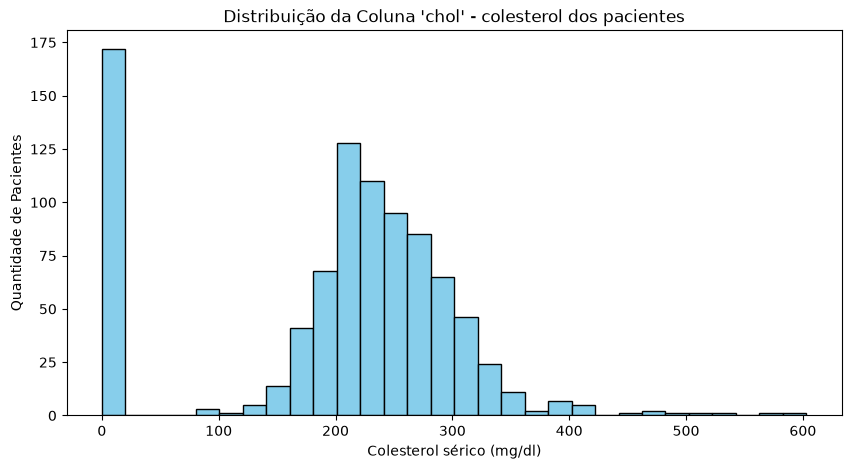

In [603]:
plt.figure(figsize=(10, 5))

plt.hist(df["chol"].dropna(), bins=30, color='skyblue', edgecolor='black')

plt.title("Distribuição da Coluna 'chol' - colesterol dos pacientes")
plt.xlabel("Colesterol sérico (mg/dl)")
plt.ylabel("Quantidade de Pacientes")

plt.show()

"O que salta aos olhos no histograma?" -> O que mais chama atenção é a quantidade de pacientes com colesterol = 0, ou seja, muito provavelmente seus dados na coluna "chol" não foram corretamente registrados (pois fisiologicamente é impossível alguém estar com colesterol = 0).

**PERGUNTAS:**
- Por que `fbs` e `exang` são `object` e não `bool`? Porque uma coluna booleana não aceita valores nan, ou seja, não consegue guardar valores faltantes, então o pandas as joga para "object"
- Qual outra coluna tem zero impossível na linha `min`? `chol`, pois colesterol sérico igual a 0 não é fisiologicamente plausível 
- Se juntar 1 a 4 como doente, qual é o % de doentes? 55.3%, como mostra o cálculo.
- A coluna `id` deveria entrar no modelo? Não é recomendado, pois os valores não vão contribuir em nada para a predição. Um paciente de id = 4 naõ tem mais chance de ter uma doença cardiaca do que um paciente de id = 2. Para não atrapalhar, melhor desconsiderar.

**Suíça: quantidade de pacientes, chol = 0 e percentual de doentes**

In [604]:
suica = df[df["dataset"] == "Switzerland"].copy() # .copy() para evitar o SettingWithCopyWarning
print(f"Total de pacientes: {len(suica)}")

chol_zero_suica = suica[suica["chol"] == 0]
print(f"Pacientes com colesterol igual a zero: {len(chol_zero_suica)}")

doente_chol_zero = chol_zero_suica["num"] > 0

percentual_doentes = (
    doente_chol_zero.sum() / len(chol_zero_suica)
    ) * 100 

print(f"Percentual de doentes entre eles: {percentual_doentes:.1f}%")



Total de pacientes: 123
Pacientes com colesterol igual a zero: 123
Percentual de doentes entre eles: 93.5%


**Agora, ca = 0 e percentual de doentes em cada hospital**

In [605]:
# Filtrar registros com ca nulo
ca_nulos = df[df["ca"].isnull()].copy()

print(f"Total de registros com ca nulo: {len(ca_nulos)}")

# Quantidade de registros com ca nulo por hospital
nulos_por_hospital = ca_nulos["dataset"].value_counts()

# Percentual de cada hospital em relação ao total de nulos
percentual_nulos = (
    ca_nulos["dataset"].value_counts(normalize=True) * 100
)

# Desconsiderar pacientes sem diagnóstico informado
ca_nulos_validos = ca_nulos.dropna(subset=["num"])

# Quantidade de doentes com ca nulo por hospital
doentes_por_hospital = (
    ca_nulos_validos[ca_nulos_validos["num"] > 0]
    ["dataset"].value_counts()
)

# Total de pacientes com ca nulo e diagnóstico conhecido por hospital
total_validos = ca_nulos_validos["dataset"].value_counts()

# Percentual de doentes entre os pacientes com ca nulo
percentual_doentes = (
    doentes_por_hospital / total_validos * 100
)

# Consolidar os resultados
resumo = pd.DataFrame({
    "Pacientes com ca nulo": nulos_por_hospital,
    "% dos nulos totais": percentual_nulos,
    "Doentes com ca nulo": doentes_por_hospital,
    "% de doentes entre ca nulo": percentual_doentes
}).fillna(0)

resumo = resumo.round(1)

display(resumo)



Total de registros com ca nulo: 611


,Pacientes com ca nulo,% dos nulos totais,Doentes com ca nulo,% de doentes entre ca nulo
dataset,,,,
Cleveland,5,0.8,1,20.0
Hungary,290,47.5,105,36.2
Switzerland,118,19.3,111,94.1
VA Long Beach,198,32.4,148,74.7


**Veja o menor e o maior id de cada hospital (groupby + min/max). Depois responda: o que um modelo aprenderia com id > 597?**

In [606]:
# Resumo dos IDs por hospital
resumo_id = df.groupby("dataset")["id"].agg(
    ["count", "min", "max"]
)

display(resumo_id.sort_values("min"))

,count,min,max
dataset,,,
Cleveland,304,1,304
Hungary,293,305,597
Switzerland,123,598,720
VA Long Beach,200,721,920


**Filtrar os pacientes com `id` > 597 e contar quantos vêm de cada hospital**

In [607]:
# Filtrar registros com id maior que 597

id_maior_597 = df[df["id"] > 597]

print(f"Total de registros com id maior que 597: {len(id_maior_597)}")
print("Quantidade por hospital:")

display(id_maior_597["dataset"].value_counts().to_frame("Quantidade de pacientes")) # display() para melhor visualização no Jupyter Notebook


Total de registros com id maior que 597: 323
Quantidade por hospital:


,Quantidade de pacientes
dataset,
VA Long Beach,200
Switzerland,123


**Calcular a porcentagem de doentes entre os pacientes com `id` > 597**

In [608]:
# calcular percentual de doentes

dados_validos = id_maior_597.dropna(subset=["num"])

percentual_doentes = (dados_validos["num"] > 0).mean() * 100

print(f"Percentual de doentes entre os pacientes com id maior que 597: {percentual_doentes:.1f}%")


Percentual de doentes entre os pacientes com id maior que 597: 81.7%


**Comparar a porcentagem de doentes entre `id` ≤ 597 e `id` > 597**

In [609]:
#

comparacao = df.dropna(subset=["num"]).copy()

comparacao["faixa_id"] = comparacao["id"].apply(
    lambda x: "ID > 597" if x > 597 else "ID <= 597"
)

proporcao = (
    comparacao.groupby("faixa_id")["num"]
    .apply(lambda x: (x > 0).mean() * 100)
)

display(proporcao.round(1).to_frame("Percentual de doentes"))

,Percentual de doentes
faixa_id,
ID <= 597,41.0
ID > 597,81.7


Ao analisar as tabelas, pude concluir que um modelo poderia aprender que pacientes com id > 597 têm maior probabilidade de apresentar doença. Porém, essa associação não representa uma característica clínica. Ela ocorre porque os ids maiores pertencem a hospitais que, nessa amostra, apresentam uma proporção maior de pacientes doentes. Basicamente o modelo estaria se baseando na origem dos dados, e não nas características da doença. 

Eu acho melhor excluir a coluna de ids das variáveis preditoras, mandento-a somente como identificadora dos registros.

**Armadilhas**

1. confundimento e dependência dos dados - o modelo pode aprender pela origem dos dados (id), e nao pelas características da doença (outras variáveis), como citei anteriormente;
2. o modelo pode aprender que chol = 0 é uma informação clínica real, e, com isso, aprender padrões incorretos. Nem todo zero é válido, por isso é bom investigar qual quais são dados reais e quais são dadois não informados;
3. o modelo pode aprender que pacientes de determinados hospitais têm mais probablididades de serem doentes, e, assim, voltamos ao problema do item .1: aprender pela origem dos dados, e não pelas suas características clínicas.